# Local-patch, fallback, and equivalent-resistance review

Read-only investigation of the current anchored outputs for examples **22, 37, 41, and 48**. The notebook does not regenerate networks or modify experiment outputs.

The five review sections are:

1. Full-raster fallback argument failure in examples 37 and 48.
2. Missing hydraulic-anchor matches after panelized fallback in example 41.
3. Equivalent-resistance solver convergence in example 37.
4. Extreme $\Lambda_K$ for example 41, unit 126.
5. Inventory and representative maps for every fallback reason.


In [3]:
from pathlib import Path
import importlib
import inspect
import json
import re
import sys

import geopandas as gpd
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import rasterio
from IPython.display import Markdown, display
from plotly.subplots import make_subplots


def find_repo_root(start=None):
    origin = Path(start or Path.cwd()).expanduser().resolve()
    for candidate in (origin, *origin.parents):
        if (candidate / 'network_variants').is_dir() and (candidate / 'RAPID').is_dir():
            return candidate
    raise FileNotFoundError(f'Could not find repository above {origin}.')


REPO_ROOT = find_repo_root()
OUTPUT_ROOT = REPO_ROOT / 'network_variants/output'
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from network_variants import local_patch_fallback_diagnostics as fallback_diag
importlib.reload(fallback_diag)

EXAMPLE_IDS = ('22', '37', '41', '48')
MODES = ('indep', 'compound_bubbles')


def read_json(path):
    path = Path(path)
    return json.loads(path.read_text()) if path.exists() else None


def one_path(directory, pattern):
    paths = sorted(path for path in Path(directory).glob(pattern) if not path.name.startswith('._'))
    if len(paths) != 1:
        raise FileNotFoundError(f'Expected one {pattern!r} below {directory}, found {len(paths)}.')
    return paths[0]


def simplified_for_display(frame, tolerance_m=5.0):
    if frame is None:
        return None
    result = frame.copy()
    line_mask = result.geometry.geom_type.isin(['LineString', 'MultiLineString'])
    result.loc[line_mask, 'geometry'] = result.loc[line_mask, 'geometry'].simplify(tolerance_m, preserve_topology=True)
    return result


def experiment_dir(example_id, mode='indep'):
    example = f'{int(example_id):02d}' if str(example_id).isdigit() else str(example_id)
    return OUTPUT_ROOT / f'{example}_{mode}__anchored'


def fallback_category(reason):
    reason = str(reason or '')
    if 'cycle rank' in reason:
        return 'cycle-rank/topology validation'
    if 'same reference-centerline projection' in reason:
        return 'collar projection degeneracy'
    if 'unauthorized_main_water' in reason:
        return 'crop-edge water contact'
    if 'Dissolving computational cut interfaces' in reason:
        return 'invalid realized source/sink topology'
    if 'No local link or node lies within' in reason:
        return 'anchored-boundary proximity'
    return 'other'


FALLBACK_DESCRIPTIONS = {
    'cycle-rank/topology validation': (
        'The final anchored graph did not remove exactly the cycle rank represented by the selected parent unit. ',
        'Check selected-parent membership, raw local topology, anchored trimming, and the fallback result.'
    ),
    'collar projection degeneracy': (
        'The inner and outer collar nodes project to the same position on the reference centerline, so the outward cut direction is undefined. ',
        'Check nested/outer-domain context and whether a larger closed domain resolves the collar.'
    ),
    'crop-edge water contact': (
        'Main connected water touches the local crop edge outside the two authorized bank cuts. ',
        'Check whether another connected channel enters the crop and whether the outer domain or halo should expand.'
    ),
    'invalid realized source/sink topology': (
        'After computational cut interfaces were dissolved, the realized splice had more than one graph source and sink. ',
        'Inspect computational-only terminals and retained external continuations before anchoring.'
    ),
    'anchored-boundary proximity': (
        'No raw local link or node lies within the strict tolerance of a required scientific parent boundary. ',
        'Compare the exact parent node, nearest raw point, and whether a projection/split is geometrically supported.'
    ),
    'other': ('The saved reason is not in the current five-category catalog. ', 'Read the exact exception before changing a rule.'),
}


def fallback_inventory(example_ids=EXAMPLE_IDS):
    records = []
    for example in example_ids:
        for mode in MODES:
            experiment = experiment_dir(example, mode)
            registry_path = experiment / 'state_registry.csv'
            status_by_state = {}
            if registry_path.exists():
                registry = pd.read_csv(registry_path)
                status_by_state = dict(zip(registry['state_id'].astype(str), registry['status'].astype(str)))
            paths = []
            for name in ('fallback_to_full_raster.json', 'fallback_to_panelized.json'):
                paths.extend(experiment.glob(f'states/*/variant/local_patch_attempt/{name}'))
            for path in sorted(paths):
                audit = read_json(path) or {}
                state_id = path.parents[2].name
                planning = read_json(path.parent / 'planning/local_patch_planning_result.json') or {}
                contract = planning.get('contract') or {}
                reason = str(audit.get('fallback_reason', ''))
                records.append({
                    'example_id': f'{int(example):02d}',
                    'mode': mode,
                    'state_id': state_id,
                    'selected_unit_ids': ','.join(str(v) for v in contract.get('selected_unit_ids', [])),
                    'fallback_backend': audit.get('execution_mode_used'),
                    'fallback_stage': audit.get('fallback_stage'),
                    'fallback_code': audit.get('fallback_code'),
                    'fallback_reason': reason,
                    'failure_category': fallback_category(reason),
                    'state_status': status_by_state.get(state_id, 'unknown'),
                    'fallback_completed': (path.parents[1] / 'summary/variant_manifest.json').exists(),
                })
    return pd.DataFrame.from_records(records)


def load_saved_fallback_case(example_id, mode, state_id):
    experiment = experiment_dir(example_id, mode)
    state = experiment / 'states' / str(state_id)
    attempt = state / 'variant/local_patch_attempt'
    candidates = [attempt / 'fallback_to_full_raster.json', attempt / 'fallback_to_panelized.json']
    fallback_path = next((path for path in candidates if path.exists()), None)
    if fallback_path is None:
        raise FileNotFoundError(f'No saved fallback audit below {attempt}.')
    base_directed = experiment / 'states/S000_base/variant/directed'
    case = {
        'repo_root': REPO_ROOT, 'example_id': f'{int(example_id):02d}', 'mode': mode,
        'state_id': str(state_id), 'experiment_dir': experiment, 'state_dir': state,
        'attempt_dir': attempt, 'fallback': read_json(fallback_path),
        'planning': read_json(attempt / 'planning/local_patch_planning_result.json'),
        'raster_plan': read_json(attempt / 'raster/local_patch_raster_plan.json'),
        'base_links': simplified_for_display(gpd.read_file(one_path(base_directed, '*directed_links.gpkg'))),
        'base_nodes': gpd.read_file(one_path(base_directed, '*directed_nodes.gpkg')),
        'cuts': None, 'crop': None, 'local_links': None, 'local_nodes': None,
        'merged_links': None, 'merged_nodes': None, 'local_mask_path': None,
        'final_child_links': None, 'final_child_nodes': None,
    }
    cuts = attempt / 'raster/main_bank_cuts.gpkg'
    crop = attempt / 'raster/local_patch_crop.gpkg'
    if cuts.exists(): case['cuts'] = gpd.read_file(cuts)
    if crop.exists(): case['crop'] = gpd.read_file(crop)
    rivgraph = attempt / 'variant/rivgraph'
    links = sorted(path for path in rivgraph.glob('*_links.gpkg') if not path.name.startswith('._'))
    nodes = sorted(path for path in rivgraph.glob('*_nodes.gpkg') if not path.name.startswith('._'))
    if len(links) == 1 and len(nodes) == 1:
        case['local_links'], case['local_nodes'] = simplified_for_display(gpd.read_file(links[0])), gpd.read_file(nodes[0])
    for relative in ('realized/splice/merged_links.gpkg', 'merge/merged_links.gpkg'):
        path = attempt / relative
        if path.exists(): case['merged_links'] = simplified_for_display(gpd.read_file(path)); break
    for relative in ('realized/splice/merged_nodes.gpkg', 'merge/merged_nodes.gpkg'):
        path = attempt / relative
        if path.exists(): case['merged_nodes'] = gpd.read_file(path); break
    mask = attempt / 'variant/mask/local_collapsed_mask.tif'
    if mask.exists(): case['local_mask_path'] = mask
    final_directed = state / 'variant/directed'
    final_links = sorted(path for path in final_directed.glob('*directed_links.gpkg') if not path.name.startswith('._'))
    final_nodes = sorted(path for path in final_directed.glob('*directed_nodes.gpkg') if not path.name.startswith('._'))
    if len(final_links) == 1 and len(final_nodes) == 1:
        case['final_child_links'], case['final_child_nodes'] = simplified_for_display(gpd.read_file(final_links[0])), gpd.read_file(final_nodes[0])
    return case


def add_anchor_overlay(figure, case, anchor_ids):
    parent = case['base_nodes'].loc[case['base_nodes']['id_node'].astype(int).isin(anchor_ids)]
    if parent.empty:
        return figure
    figure.add_trace(go.Scattergl(
        x=parent.geometry.x, y=parent.geometry.y, mode='markers+text',
        marker=dict(size=15, color='gold', symbol='diamond', line=dict(color='black', width=1)),
        text=[f'parent hydraulic anchor {int(v)}' for v in parent['id_node']], textposition='top center',
        name='parent hydraulic anchors', hovertemplate='%{text}<extra></extra>',
    ))
    return figure


print('Repository:', REPO_ROOT)
print('Output root:', OUTPUT_ROOT.resolve())


Repository: /Users/6256481/Code/river-hierarchy
Output root: /Volumes/PhD/river_hierarchy/network_variants/output


## Current run overview

This is a compact structural overview. `complete EQ` counts rows whose selected hydraulic domain completed and whose `Lambda_K` is finite.


In [2]:
overview = []
for example in EXAMPLE_IDS:
    for mode in MODES:
        experiment = experiment_dir(example, mode)
        manifest = read_json(experiment / 'experiment_manifest.json')
        if manifest is None:
            continue
        eq_path = experiment / 'equivalent_transition_registry.csv'
        eq = pd.read_csv(eq_path) if eq_path.exists() else pd.DataFrame()
        complete_eq = 0
        if not eq.empty and {'selected_domain_status', 'Lambda_K'}.issubset(eq.columns):
            complete_eq = int((eq['selected_domain_status'].eq('complete') & pd.to_numeric(eq['Lambda_K'], errors='coerce').notna()).sum())
        overview.append({
            'example_id': example, 'mode': mode,
            'child_states': int(manifest.get('n_states', 1)) - 1,
            'complete_states': int(manifest.get('n_complete_states', 1)) - 1,
            'failed_states': int(manifest.get('n_failed_states', 0)),
            'EQ rows': len(eq), 'complete EQ': complete_eq,
            'stop_reason': manifest.get('stop_reason'),
        })
overview = pd.DataFrame(overview)
display(overview)


,example_id,mode,child_states,complete_states,failed_states,EQ rows,complete EQ,stop_reason
0,22,indep,331,331,0,331,331,all_base_units_processed
1,22,compound_bubbles,7,7,0,7,7,all_compound_bubbles_processed
2,37,indep,325,312,13,312,312,all_base_units_processed
3,37,compound_bubbles,2,2,0,2,2,all_compound_bubbles_processed
4,41,indep,136,136,0,136,118,all_base_units_processed
5,41,compound_bubbles,18,18,0,18,14,all_compound_bubbles_processed
6,48,indep,62,61,1,61,61,all_base_units_processed
7,48,compound_bubbles,10,10,0,10,10,all_compound_bubbles_processed


## 1. Full-raster fallback argument failure — examples 37 and 48

The local attempt correctly rejected unsafe output and requested a full-raster fallback. The fallback itself then failed before scientific processing because `_build_child_state()` supplied `exclude_closed_two_link_replacement`, while `generate_network_variant()` does not accept that keyword. This section separates the **original local safety reason** from the **technical fallback failure**.


In [3]:
from network_variants.variant_generation import generate_network_variant

argument_name = 'exclude_closed_two_link_replacement'
signature = inspect.signature(generate_network_variant)
display(pd.Series({
    'fallback function': 'generate_network_variant',
    'argument supplied by child dispatcher': argument_name,
    'argument accepted by fallback function': argument_name in signature.parameters,
    'function signature': str(signature),
}, name='value').to_frame())

fallbacks = fallback_inventory(('37', '48'))
failed_fallbacks = fallbacks.loc[fallbacks['state_status'].eq('failed')].copy()
failure_rows = []
for record in failed_fallbacks.to_dict('records'):
    failure = read_json(experiment_dir(record['example_id'], record['mode']) / 'states' / record['state_id'] / 'state_failure.json') or {}
    failure_rows.append({**record, 'final_state_error': failure.get('error')})
failed_fallbacks = pd.DataFrame(failure_rows)
display(failed_fallbacks[[
    'example_id', 'state_id', 'selected_unit_ids', 'failure_category',
    'fallback_reason', 'final_state_error'
]])
display(failed_fallbacks.groupby(['example_id', 'failure_category']).size().rename('states').reset_index())


,value
fallback function,generate_network_variant
argument supplied by child dispatcher,exclude_closed_two_link_replacement
argument accepted by fallback function,False
function signature,"(*, cleaned_mask_path: 'str | Path', reviewed_..."


,example_id,state_id,selected_unit_ids,failure_category,fallback_reason,final_state_error
0,37,S004_unit_9,9,cycle-rank/topology validation,Final shared-anchored local graph is inconsist...,TypeError: generate_network_variant() got an u...
1,37,S007_unit_215,215,collar projection degeneracy,Inner and outer nodes of collar 641 have the s...,TypeError: generate_network_variant() got an u...
2,37,S013_unit_251,251,collar projection degeneracy,Inner and outer nodes of collar 748 have the s...,TypeError: generate_network_variant() got an u...
3,37,S027_unit_267,267,invalid realized source/sink topology,Dissolving computational cut interfaces produc...,TypeError: generate_network_variant() got an u...
4,37,S041_unit_84,84,collar projection degeneracy,Inner and outer nodes of collar 241 have the s...,TypeError: generate_network_variant() got an u...
5,37,S048_unit_169,169,cycle-rank/topology validation,Final shared-anchored local graph is inconsist...,TypeError: generate_network_variant() got an u...
6,37,S061_unit_311,311,collar projection degeneracy,Inner and outer nodes of collar 923 have the s...,TypeError: generate_network_variant() got an u...
7,37,S076_unit_228,228,collar projection degeneracy,Inner and outer nodes of collar 672 have the s...,TypeError: generate_network_variant() got an u...
8,37,S094_unit_296,296,collar projection degeneracy,Inner and outer nodes of collar 876 have the s...,TypeError: generate_network_variant() got an u...
9,37,S108_unit_233,233,crop-edge water contact,unauthorized_main_water_crop_edge_contact,TypeError: generate_network_variant() got an u...


,example_id,failure_category,states
0,37,collar projection degeneracy,7
1,37,crop-edge water contact,2
2,37,cycle-rank/topology validation,3
3,37,invalid realized source/sink topology,1
4,48,cycle-rank/topology validation,1


In [27]:
# Change this index to review any of the 14 failed full-raster fallbacks.
FULL_FALLBACK_CASE_INDEX = 0
record = failed_fallbacks.iloc[FULL_FALLBACK_CASE_INDEX].to_dict()
display(Markdown(f"### {record['example_id']} {record['state_id']} — {record['failure_category']}"))
display(pd.Series(record, name='value').to_frame())
display(record['fallback_reason'])
display(record['final_state_error'])
case = load_saved_fallback_case(record['example_id'], record['mode'], record['state_id'])
display(fallback_diag.plotly_failure_case(case))


### 37 S004_unit_9 — cycle-rank/topology validation

,value
example_id,37
mode,indep
state_id,S004_unit_9
selected_unit_ids,9
fallback_backend,full_raster
fallback_stage,execution
fallback_code,ValueError
fallback_reason,Final shared-anchored local graph is inconsist...
failure_category,cycle-rank/topology validation
state_status,failed


'Final shared-anchored local graph is inconsistent with the raster edit: selected-parent cycle rank=1, observed cycle-rank reduction=0, parent cycle rank=326, anchored cycle rank=326.'

"TypeError: generate_network_variant() got an unexpected keyword argument 'exclude_closed_two_link_replacement'"

## 2. Panelized fallback hydraulic-anchor matching — example 41

All panelized fallback networks passed structural and direction validation and are RAPID-ready. Equivalent-resistance comparison is nevertheless missing when the generic child-to-parent match table contains no stable match for one or both hydraulic-domain anchors. The scientific network can therefore be valid while the matched-domain calculation remains incomplete.


In [34]:
eq41_frames = []
for mode in MODES:
    path = experiment_dir('41', mode) / 'equivalent_transition_registry.csv'
    if path.exists():
        frame = pd.read_csv(path)
        frame['mode'] = mode
        eq41_frames.append(frame)
eq41 = pd.concat(eq41_frames, ignore_index=True)
eq41_failed = eq41.loc[eq41['selected_domain_status'].ne('complete')].copy()
fallback41 = fallback_inventory(('41',))
eq41_failed = eq41_failed.merge(
    fallback41[['mode', 'state_id', 'fallback_backend', 'failure_category', 'fallback_reason']],
    left_on=['mode', 'child_state_id'], right_on=['mode', 'state_id'], how='left', validate='1:1'
)
display(eq41_failed[[
    'mode', 'child_state_id', 'selected_unit_ids', 'fallback_backend',
    'failure_category', 'selected_domain_error'
]])
display(eq41_failed.groupby(['mode', 'failure_category']).size().rename('missing_EQ').reset_index())


,mode,child_state_id,selected_unit_ids,fallback_backend,failure_category,selected_domain_error
0,indep,S002_unit_128,128,panelized,invalid realized source/sink topology,ValueError: No stable child-node match exists ...
1,indep,S009_unit_45,45,panelized,invalid realized source/sink topology,ValueError: No stable child-node match exists ...
2,indep,S016_unit_4,4,panelized,cycle-rank/topology validation,ValueError: No stable child-node match exists ...
3,indep,S017_unit_115,115,panelized,crop-edge water contact,ValueError: No stable child-node match exists ...
4,indep,S024_unit_89,89,panelized,invalid realized source/sink topology,ValueError: No stable child-node match exists ...
5,indep,S030_unit_81,81,panelized,cycle-rank/topology validation,ValueError: No stable child-node match exists ...
6,indep,S036_unit_134,134,panelized,cycle-rank/topology validation,ValueError: No stable child-node match exists ...
7,indep,S042_unit_56,56,panelized,anchored-boundary proximity,ValueError: No stable child-node match exists ...
8,indep,S046_unit_18,18,panelized,cycle-rank/topology validation,ValueError: No stable child-node match exists ...
9,indep,S049_unit_70,70,panelized,cycle-rank/topology validation,ValueError: No stable child-node match exists ...


,mode,failure_category,missing_EQ
0,compound_bubbles,anchored-boundary proximity,1
1,compound_bubbles,crop-edge water contact,3
2,indep,anchored-boundary proximity,4
3,indep,crop-edge water contact,5
4,indep,cycle-rank/topology validation,5
5,indep,invalid realized source/sink topology,4


In [45]:
# Review a missing-anchor case. Unit 128 is the default.
ANCHOR_CASE_STATE = 'S072_unit_124'
anchor_row = eq41_failed.loc[eq41_failed['child_state_id'].eq(ANCHOR_CASE_STATE)].iloc[0].to_dict()
mode = str(anchor_row['mode'])
case = load_saved_fallback_case('41', mode, ANCHOR_CASE_STATE)
match = re.search(r'anchors \[([^]]+)\]', str(anchor_row['selected_domain_error']))
anchor_ids = [int(value.strip()) for value in match.group(1).split(',')] if match else []
node_match_path = experiment_dir('41', mode) / 'states' / ANCHOR_CASE_STATE / 'variant/matching/node_match.csv'
node_match = pd.read_csv(node_match_path)
child_nodes = case['final_child_nodes']
anchor_audit = []
for anchor_id in anchor_ids:
    parent_row = case['base_nodes'].loc[case['base_nodes']['id_node'].astype(int).eq(anchor_id)].iloc[0]
    distances = child_nodes.geometry.distance(parent_row.geometry)
    nearest_index = distances.idxmin()
    nearest = child_nodes.loc[nearest_index]
    matched_parent_ids = pd.to_numeric(node_match['matched_parent_node_id'], errors='coerce')
    stable = node_match.loc[matched_parent_ids.eq(anchor_id)]
    anchor_audit.append({
        'parent_anchor_id': anchor_id,
        'stable_match_count': len(stable),
        'matched_child_ids': stable['child_id_node'].astype(int).tolist(),
        'nearest_child_id': int(nearest['id_node']),
        'nearest_child_distance_m': float(distances.loc[nearest_index]),
    })
anchor_audit = pd.DataFrame(anchor_audit)
display(pd.Series(anchor_row, name='value').to_frame())
display(anchor_audit)
figure = fallback_diag.plotly_failure_case(case)
figure = add_anchor_overlay(figure, case, anchor_ids)
figure.update_layout(title=f'Example 41 {ANCHOR_CASE_STATE} — local failure, panelized result, and missing EQ anchors')
display(figure)


,value
transition_id,T072
parent_state_id,S000_base
child_state_id,S072_unit_124
match_method,smallest_closed_hydraulic_domain_failed
comparison_scope,selected_hydraulic_domain
...,...
mode,indep
state_id,S072_unit_124
fallback_backend,panelized
failure_category,anchored-boundary proximity


,parent_anchor_id,stable_match_count,matched_child_ids,nearest_child_id,nearest_child_distance_m
0,251,0,[],251,3101.011035
1,255,0,[],251,78.165882


## 3. Equivalent-resistance solver convergence — example 37

A finite $\Lambda_K$ is not the same as a validated solve. This section distinguishes final solver success, primary-solver success, residual magnitude, and the finite values currently present in the registry. Rows marked unsuccessful should not be silently treated as validated observations.


In [8]:
eq37 = pd.read_csv(experiment_dir('37', 'indep') / 'equivalent_transition_registry.csv')
eq37['solver_pair_success'] = eq37['parent_solver_success'].eq(True) & eq37['child_solver_success'].eq(True)
eq37['Lambda_K_finite'] = np.isfinite(pd.to_numeric(eq37['Lambda_K'], errors='coerce'))
eq37['max_polish_residual_relative'] = eq37[[
    'parent_polish_residual_relative', 'child_polish_residual_relative'
]].apply(pd.to_numeric, errors='coerce').max(axis=1)
summary37 = pd.Series({
    'EQ rows': len(eq37),
    'finite Lambda_K': int(eq37['Lambda_K_finite'].sum()),
    'parent solver success': int(eq37['parent_solver_success'].eq(True).sum()),
    'child solver success': int(eq37['child_solver_success'].eq(True).sum()),
    'both final solvers successful': int(eq37['solver_pair_success'].sum()),
    'maximum recorded polish residual': eq37['max_polish_residual_relative'].max(),
}, name='value')
display(summary37.to_frame())
worst37 = eq37.sort_values('max_polish_residual_relative', ascending=False).head(20)
display(worst37[[
    'child_state_id', 'selected_unit_ids', 'hydraulic_domain_type',
    'parent_solver_success', 'child_solver_success',
    'parent_polish_residual_relative', 'child_polish_residual_relative',
    'Lambda_K', 'parent_domain_n_links', 'child_domain_n_links'
]])


,value
EQ rows,312.000000
finite Lambda_K,312.000000
parent solver success,256.000000
child solver success,37.000000
both final solvers successful,36.000000
maximum recorded polish residual,0.014107


,child_state_id,selected_unit_ids,hydraulic_domain_type,parent_solver_success,child_solver_success,parent_polish_residual_relative,child_polish_residual_relative,Lambda_K,parent_domain_n_links,child_domain_n_links
195,S208_unit_166,166,containing_compound_context,True,False,0.000962,0.014107,0.877515,946,945
109,S120_unit_235,235,containing_compound_context,True,False,0.000962,0.012267,0.971124,946,947
101,S112_unit_33,33,containing_compound_context,True,False,0.000962,0.009522,0.996717,946,946
154,S166_unit_298,298,containing_compound_context,True,False,0.000962,0.008801,1.010934,946,948
305,S319_unit_107,107,containing_compound_context,True,False,0.000962,0.008571,0.977886,946,947
214,S227_unit_203,203,containing_compound_context,True,False,0.000962,0.008435,0.988319,946,947
296,S310_unit_93,93,containing_compound_context,True,False,0.000962,0.008037,0.982147,946,948
143,S155_unit_261,261,containing_compound_context,True,False,0.000962,0.007799,0.991943,946,947
277,S291_unit_209,209,containing_compound_context,True,False,0.000962,0.007663,0.979358,946,952
244,S257_unit_45,45,containing_compound_context,True,False,0.000962,0.007637,0.946206,946,948


In [9]:
plot37 = eq37.copy()
plot37['solver_status'] = np.where(plot37['solver_pair_success'], 'both successful', 'one or both unsuccessful')
plot37['residual_for_plot'] = plot37['max_polish_residual_relative'].clip(lower=1e-12)
figure = make_subplots(rows=1, cols=2, subplot_titles=('Lambda_K by solver status', 'Residual versus Lambda_K'))
for status, color in [('both successful', '#2ca02c'), ('one or both unsuccessful', '#d62728')]:
    subset = plot37.loc[plot37['solver_status'].eq(status)]
    figure.add_trace(go.Histogram(
        x=subset['Lambda_K'], name=status, marker_color=color, opacity=0.65, nbinsx=45, legendgroup=status
    ), row=1, col=1)
    figure.add_trace(go.Scattergl(
        x=subset['residual_for_plot'], y=subset['Lambda_K'], mode='markers', name=status,
        marker=dict(color=color, size=7, opacity=0.75), legendgroup=status, showlegend=False,
        customdata=np.column_stack((subset['child_state_id'], subset['selected_unit_ids'])),
        hovertemplate='state=%{customdata[0]}<br>unit=%{customdata[1]}<br>residual=%{x:.3g}<br>Lambda_K=%{y:.6g}<extra></extra>',
    ), row=1, col=2)
figure.update_xaxes(type='log', title_text='Lambda_K', row=1, col=1)
figure.update_xaxes(type='log', title_text='maximum polish residual (relative)', row=1, col=2)
figure.update_yaxes(type='log', title_text='Lambda_K', row=1, col=2)
figure.update_layout(template='plotly_white', barmode='overlay', height=550, width=1250, title='Example 37 equivalent-resistance convergence audit')
display(figure)


## 4. Extreme Lambda_K — example 41, unit 126

Unit 126 has $\Lambda_K \approx 400.6$. Both solvers report success, so this is not automatically a numerical failure. The review below compares the exact matched hydraulic-domain tables and maps the parent and child domains. Hover over links to inspect length and routing width.


In [10]:
UNIT126_STATE = 'S130_unit_126'
unit126_root = experiment_dir('41', 'indep') / 'states' / UNIT126_STATE
comparison126 = pd.read_csv(unit126_root / 'equivalent_resistance/bubble_equivalent_state_comparison.csv')
domain126 = pd.read_csv(unit126_root / 'equivalent_resistance/selected_hydraulic_domain_links.csv')
display(comparison126.T.rename(columns={0: 'value'}))
domain_summary126 = domain126.groupby('domain_role').agg(
    n_links=('id_link', 'size'),
    total_length_m=('len', 'sum'),
    median_routing_width_m=('wid_adj_routing', 'median'),
    minimum_routing_width_m=('wid_adj_routing', 'min'),
    maximum_routing_width_m=('wid_adj_routing', 'max'),
).reset_index()
display(domain_summary126)
display(domain126.sort_values(['domain_role', 'wid_adj_routing']).reset_index(drop=True))


,value
transition_id,T130
parent_state_id,S000_base
child_state_id,S130_unit_126
match_method,smallest_closed_hydraulic_domain__matched_pare...
comparison_scope,selected_hydraulic_domain
...,...
residual_relative_after,0.0
Lambda_K,400.602986
Lambda_G,0.002496
percent_change_K,39960.29855


,domain_role,n_links,total_length_m,median_routing_width_m,minimum_routing_width_m,maximum_routing_width_m
0,child,20,57227.812252,346.434766,85.396466,1849.739350
1,parent,29,83940.113260,345.538408,71.315444,1669.446624


,transition_id,domain_role,state_id,id_link,id_us_node,id_ds_node,len,wid_adj_routing,wid_adj_wet,wid_adj_total
0,T130,child,S130_unit_126,409,278,274,2000.181438,85.396466,85.396466,89.767264
1,T130,child,S130_unit_126,418,250,278,3767.604350,85.396466,85.396466,89.767264
2,T130,child,S130_unit_126,413,280,275,1481.147014,97.918231,97.918231,102.305106
3,T130,child,S130_unit_126,420,254,280,2455.755258,97.918231,97.918231,102.305106
4,T130,child,S130_unit_126,411,276,275,703.703987,140.529429,1674.091450,4549.996038
5,T130,child,S130_unit_126,382,264,261,1015.844380,195.318692,195.318692,199.740553
6,T130,child,S130_unit_126,417,277,283,4279.643693,213.529066,213.529066,217.957283
7,T130,child,S130_unit_126,423,283,239,10221.415982,213.529066,213.529066,217.957283
8,T130,child,S130_unit_126,383,264,261,949.925657,229.032812,229.032812,233.466120
9,T130,child,S130_unit_126,412,279,276,1588.751712,346.434766,346.434766,350.883034


In [11]:
base_directed = experiment_dir('41', 'indep') / 'states/S000_base/variant/directed'
child_directed = unit126_root / 'variant/directed'
base_links = gpd.read_file(one_path(base_directed, '*directed_links.gpkg'))
child_links = gpd.read_file(one_path(child_directed, '*directed_links.gpkg')).to_crs(base_links.crs)
parent_ids = set(domain126.loc[domain126['domain_role'].eq('parent'), 'id_link'].astype(int))
child_ids = set(domain126.loc[domain126['domain_role'].eq('child'), 'id_link'].astype(int))
parent_domain = base_links.loc[base_links['id_link'].astype(int).isin(parent_ids)].merge(
    domain126.loc[domain126['domain_role'].eq('parent')].drop(columns=['domain_role', 'state_id']),
    on='id_link', suffixes=('', '_domain'), validate='1:1'
)
child_domain = child_links.loc[child_links['id_link'].astype(int).isin(child_ids)].merge(
    domain126.loc[domain126['domain_role'].eq('child')].drop(columns=['domain_role', 'state_id']),
    on='id_link', suffixes=('', '_domain'), validate='1:1'
)
parent_domain = simplified_for_display(parent_domain)
child_domain = simplified_for_display(child_domain)
audit_area = parent_domain.geometry.union_all().union(child_domain.geometry.union_all()).buffer(500)
figure = make_subplots(rows=1, cols=2, shared_xaxes=True, shared_yaxes=True, subplot_titles=('parent matched hydraulic domain', 'child matched hydraulic domain'))

def add_link_frame(frame, column, name, color, width, dash='solid', opacity=1.0):
    first = True
    for row in frame.itertuples(index=False):
        parts = list(row.geometry.geoms) if row.geometry.geom_type == 'MultiLineString' else [row.geometry]
        for geometry in parts:
            x, y = geometry.xy
            link_id = getattr(row, 'id_link', '')
            us_node = getattr(row, 'id_us_node', '?')
            ds_node = getattr(row, 'id_ds_node', '?')
            length = getattr(row, 'len_domain', getattr(row, 'len', np.nan))
            width_value = getattr(row, 'wid_adj_routing_domain', getattr(row, 'wid_adj_routing', np.nan))
            hover = (f'{name}<br>link {link_id}<br>{us_node} → {ds_node}'
                     f'<br>length={length:.2f} m<br>routing width={width_value:.2f} m')
            figure.add_trace(go.Scattergl(
                x=list(x), y=list(y), mode='lines', name=name, legendgroup=name, showlegend=first,
                line=dict(color=color, width=width, dash=dash), opacity=opacity, hovertemplate=hover + '<extra></extra>'
            ), row=1, col=column)
            first = False

add_link_frame(parent_domain, 1, 'parent matched domain', '#1f77b4', 4)
add_link_frame(child_domain, 2, 'child matched domain', '#8e5cc2', 4)
bounds = audit_area.bounds
figure.update_xaxes(range=[bounds[0], bounds[2]], scaleanchor='y', scaleratio=1)
figure.update_yaxes(range=[bounds[1], bounds[3]])
figure.update_layout(template='plotly_white', height=760, width=1400, title='Example 41, unit 126 — exact domains used for Lambda_K = 400.603', legend=dict(orientation='h'))
display(figure)


## 5. Why did local processing fall back?

A fallback is not itself a failed state. It means a conservative local rule rejected the attempted patch. Examples 22 and 41 show successful fallback execution; examples 37 and 48 show a subsequent technical failure in the full-raster dispatcher. This section gives counts and at least one saved example of every reason currently present.


In [12]:
all_fallbacks = fallback_inventory()
fallback_counts = all_fallbacks.groupby([
    'failure_category', 'example_id', 'mode', 'fallback_backend', 'state_status'
]).size().rename('states').reset_index()
display(fallback_counts)

representatives = (all_fallbacks.sort_values(['failure_category', 'example_id', 'state_id'])
                   .groupby('failure_category', as_index=False).first())
representatives['description'] = representatives['failure_category'].map(lambda value: ''.join(FALLBACK_DESCRIPTIONS[value]))
display(representatives[[
    'failure_category', 'description', 'example_id', 'mode', 'state_id',
    'fallback_backend', 'state_status', 'fallback_reason'
]])


,failure_category,example_id,mode,fallback_backend,state_status,states
0,anchored-boundary proximity,22,indep,full_raster,complete,1
1,anchored-boundary proximity,41,compound_bubbles,panelized,complete,1
2,anchored-boundary proximity,41,indep,panelized,complete,16
3,collar projection degeneracy,22,indep,full_raster,complete,5
4,collar projection degeneracy,37,indep,full_raster,failed,7
5,crop-edge water contact,22,indep,full_raster,complete,1
6,crop-edge water contact,37,indep,full_raster,failed,2
7,crop-edge water contact,41,compound_bubbles,panelized,complete,3
8,crop-edge water contact,41,indep,panelized,complete,10
9,cycle-rank/topology validation,22,indep,full_raster,complete,5


,failure_category,description,example_id,mode,state_id,fallback_backend,state_status,fallback_reason
0,anchored-boundary proximity,No raw local link or node lies within the stri...,22,indep,S216_unit_10,full_raster,complete,No local link or node lies within 79.322 m of ...
1,collar projection degeneracy,The inner and outer collar nodes project to th...,22,indep,S041_unit_119,full_raster,complete,Inner and outer nodes of collar 339 have the s...
2,crop-edge water contact,Main connected water touches the local crop ed...,22,indep,S311_unit_91,full_raster,complete,unauthorized_main_water_crop_edge_contact
3,cycle-rank/topology validation,The final anchored graph did not remove exactl...,22,indep,S011_unit_326,full_raster,complete,Final shared-anchored local graph is inconsist...
4,invalid realized source/sink topology,After computational cut interfaces were dissol...,37,indep,S027_unit_267,full_raster,failed,Dissolving computational cut interfaces produc...


In [51]:
# all_fallbacks.loc[all_fallbacks['failure_category'].eq(FALLBACK_CATEGORY)].reset_index(drop=True)

In [65]:
# Select one category from the table above.
FALLBACK_CATEGORY = 'invalid realized source/sink topology'
CATEGORY_CASE_INDEX = 0
category_cases = all_fallbacks.loc[all_fallbacks['failure_category'].eq(FALLBACK_CATEGORY)].reset_index(drop=True)
record = category_cases.iloc[CATEGORY_CASE_INDEX].to_dict()
description, review = FALLBACK_DESCRIPTIONS[FALLBACK_CATEGORY]
display(Markdown(
    f"### {record['example_id']} {record['mode']} {record['state_id']} — {FALLBACK_CATEGORY}\n\n"
    f"**Failure meaning:** {description}\n\n**Review:** {review}"
))
display(pd.Series(record, name='value').to_frame())
case = load_saved_fallback_case(record['example_id'], record['mode'], record['state_id'])
display(fallback_diag.plotly_failure_case(case))


### 37 indep S027_unit_267 — invalid realized source/sink topology

**Failure meaning:** After computational cut interfaces were dissolved, the realized splice had more than one graph source and sink. 

**Review:** Inspect computational-only terminals and retained external continuations before anchoring.

,value
example_id,37
mode,indep
state_id,S027_unit_267
selected_unit_ids,267
fallback_backend,full_raster
fallback_stage,execution
fallback_code,ValueError
fallback_reason,Dissolving computational cut interfaces produc...
failure_category,invalid realized source/sink topology
state_status,failed


In [46]:
1650/1950

0.8461538461538461

## 6. Island local-patch paired validation — example 56

The full-raster and local-patch island masks are identical, and their final directed topology and lineage signatures agree. This review isolates the small set of geometrically matched links whose final length or width products differ beyond the selected tolerance. It explicitly distinguishes **locally remeasured** links from links whose local values were deliberately inherited from the base network; an inherited link can differ from its independently remeasured full-raster counterpart without being a local edit. It is read-only: it loads the paired-comparison report and saved final products, then maps the relevant full-raster (blue) and local-patch (orange) geometries.

`ISLAND_ID` and `WIDTH_REVIEW_TOLERANCE` are deliberately editable. The default selects the only currently material mismatch, `island_56_005`.

In [4]:
from scipy.optimize import linear_sum_assignment

ISLAND_SETUP = OUTPUT_ROOT / '56_indep__anchored/island_only_setup_8connected'
if not ISLAND_SETUP.exists():
    ISLAND_SETUP = Path('/Volumes/PhD/river_hierarchy/network_variants/output/56_indep__anchored/island_only_setup_8connected')

ISLAND_ID = 'island_56_005'
WIDTH_REVIEW_TOLERANCE = 0.02

paired_report = pd.read_csv(ISLAND_SETUP / 'island_local_patch_paired_comparison.csv')
display(paired_report[[
    'island_id', 'mask_equal', 'anchor_provenance_equal',
    'topology_equal_within_geometry_tolerance', 'routing_products_ready',
    'widths_within_relative_tolerance', 'max_link_hausdorff_m',
    'wid_adj_routing_max_relative_difference',
]])

island_root = ISLAND_SETUP / 'island_reruns' / ISLAND_ID
full_manifest = read_json(island_root / 'island_run_manifest.json')
local_manifest = read_json(island_root / 'local_patch/island_local_patch_run_manifest.json')
full_paths = {key: Path(value) for key, value in full_manifest['final_paths'].items()}
local_paths = {key: Path(value) for key, value in local_manifest['final_paths'].items()}
local_variant_manifest = read_json(local_paths['variant_manifest'])
locally_recalculated_ids = set(local_variant_manifest['local_patch']['products']['summary']['recalculated_link_ids'])

full_links = gpd.read_file(full_paths['routing_width_links']).sort_values('id_link').reset_index(drop=True)
local_links = gpd.read_file(local_paths['routing_width_links']).to_crs(full_links.crs).sort_values('id_link').reset_index(drop=True)
full_lineage = pd.read_csv(full_paths['directed_links'].parent / 'link_lineage.csv').set_index('id_link')
local_lineage = pd.read_csv(local_paths['directed_links'].parent.parent / 'matching/link_lineage.csv').set_index('id_link')

hausdorff = np.asarray([
    [left.hausdorff_distance(right) for right in local_links.geometry]
    for left in full_links.geometry
], dtype=float)
full_rows, local_rows = linear_sum_assignment(hausdorff)

review_fields = ['len', 'len_adj', 'wid_adj_total', 'wid_adj_wet', 'wid_adj_dry', 'wid_adj_routing']
pair_rows = []
for full_row, local_row in zip(full_rows, local_rows):
    full_link = full_links.iloc[full_row]
    local_link = local_links.iloc[local_row]
    full_link_id = int(full_link.id_link)
    local_link_id = int(local_link.id_link)
    full_lineage_type = full_lineage.loc[full_link_id, 'lineage_type'] if full_link_id in full_lineage.index else 'anchor_split_or_unmatched'
    local_lineage_type = local_lineage.loc[local_link_id, 'lineage_type'] if local_link_id in local_lineage.index else 'anchor_split_or_unmatched'
    dominant_parent_link_id = full_lineage.loc[full_link_id, 'dominant_parent_link_id'] if full_link_id in full_lineage.index else np.nan
    pair = {
        'full_link_id': full_link_id,
        'local_link_id': local_link_id,
        'hausdorff_m': float(hausdorff[full_row, local_row]),
        'full_lineage_type': full_lineage_type,
        'local_lineage_type': local_lineage_type,
        'dominant_parent_link_id': dominant_parent_link_id,
        'local_width_evaluation_status': local_link['width_evaluation_status'],
        'local_width_source': ('locally remeasured' if local_link_id in locally_recalculated_ids else 'inherited from base'),
    }
    for field in review_fields:
        full_value = float(full_link[field])
        local_value = float(local_link[field])
        pair[f'full_{field}'] = full_value
        pair[f'local_{field}'] = local_value
        pair[f'{field}_relative_difference'] = abs(full_value - local_value) / max(abs(full_value), abs(local_value), 1e-12)
    pair_rows.append(pair)

paired_links = pd.DataFrame(pair_rows)
difference_columns = [f'{field}_relative_difference' for field in review_fields]
affected_pairs = paired_links.loc[(paired_links[difference_columns] > WIDTH_REVIEW_TOLERANCE).any(axis=1)].copy()
affected_pairs = affected_pairs.sort_values('wid_adj_routing_relative_difference', ascending=False).reset_index(drop=True)
display(Markdown(f'### {ISLAND_ID}: {len(affected_pairs)} link pairs above {WIDTH_REVIEW_TOLERANCE:.0%} relative difference'))
display(affected_pairs)


,island_id,mask_equal,anchor_provenance_equal,topology_equal_within_geometry_tolerance,routing_products_ready,widths_within_relative_tolerance,max_link_hausdorff_m,wid_adj_routing_max_relative_difference
0,island_56_005,True,True,True,True,False,30.171829,0.440505
1,island_56_011,True,True,True,True,False,30.171829,0.032856
2,island_56_013,True,True,True,True,False,30.171829,0.032856


### island_56_005: 7 link pairs above 2% relative difference

,full_link_id,local_link_id,hausdorff_m,full_lineage_type,local_lineage_type,dominant_parent_link_id,full_len,local_len,len_relative_difference,full_len_adj,...,wid_adj_total_relative_difference,full_wid_adj_wet,local_wid_adj_wet,wid_adj_wet_relative_difference,full_wid_adj_dry,local_wid_adj_dry,wid_adj_dry_relative_difference,full_wid_adj_routing,local_wid_adj_routing,wid_adj_routing_relative_difference
0,11,48,1.164153e-09,touch_fallback_1to1,touch_fallback_1to1,8.0,1315.165837,1315.165837,4.287571e-14,103.488518,...,5.288387e-01,324.742956,181.691937,0.440505,68.839938,0.000000,1.000000,324.742956,181.691937,0.440505
1,42,45,3.017183e+01,unchanged_1to1,unchanged_1to1,45.0,2058.723000,2060.498582,8.617246e-04,1625.111336,...,3.246057e-02,583.496175,564.324930,0.032856,0.000000,0.000000,0.000000,583.496175,564.324930,0.032856
2,10,46,9.331398e-10,touch_fallback_1to1,touch_fallback_1to1,11.0,1216.116275,1216.116275,1.402253e-14,1216.116275,...,4.292778e-01,762.729827,781.561845,0.024095,612.159484,0.000000,1.000000,762.729827,781.561845,0.024095
3,43,6,0.000000e+00,unchanged_1to1,unchanged_1to1,6.0,3252.822951,3252.822951,3.229399e-14,2345.459742,...,3.170751e-03,605.751999,607.701800,0.003208,0.000000,0.000000,0.000000,605.751999,607.701800,0.003208
4,45,53,1.164153e-09,unchanged_1to1,unchanged_1to1,15.0,1151.575205,1151.575205,7.838598e-13,651.583795,...,1.474810e-13,181.669749,181.691937,0.000122,0.000000,0.000000,0.000000,181.669749,181.691937,0.000122
5,8,49,1.041250e-09,anchor_split_or_unmatched,anchor_split_or_unmatched,NaN,2937.498438,2937.498438,1.950577e-14,220.052355,...,7.349704e-14,393.620526,393.590694,0.000076,1640.881391,1640.911643,0.000018,393.620526,393.590694,0.000076
6,7,50,9.331398e-10,resolved_1to1,resolved_1to1,9.0,3764.240284,3764.240284,3.370521e-13,1046.526519,...,1.175448e-13,550.796091,550.795234,0.000002,0.000000,0.000000,0.000000,550.796091,550.795234,0.000002


In [5]:
def add_geometry_trace(figure, geometry, *, name, color, dash='solid', width=4):
    geometries = list(geometry.geoms) if geometry.geom_type == 'MultiLineString' else [geometry]
    for index, line in enumerate(geometries):
        x, y = line.xy
        figure.add_trace(go.Scatter(
            x=list(x), y=list(y), mode='lines', name=name if index == 0 else None,
            legendgroup=name, showlegend=index == 0,
            line={'color': color, 'width': width, 'dash': dash},
            hovertemplate=f'{name}<extra></extra>',
        ))

island_geometry = gpd.read_file(ISLAND_SETUP / 'island_candidate_geometries.gpkg')
island_geometry = island_geometry.loc[island_geometry['island_id'].eq(ISLAND_ID)].to_crs(full_links.crs)
crop_path = island_root / 'local_patch/variant/local_patch_attempt/raster/local_patch_crop.gpkg'
crop = gpd.read_file(crop_path).to_crs(full_links.crs) if crop_path.exists() else None

figure = go.Figure()
for geometry in island_geometry.geometry.boundary:
    add_geometry_trace(figure, geometry, name='frozen island boundary', color='#7f7f7f', width=2)
if crop is not None:
    for geometry in crop.geometry.boundary:
        add_geometry_trace(figure, geometry, name='local crop boundary', color='#9467bd', dash='dot', width=2)
for record in affected_pairs.itertuples(index=False):
    full_geometry = full_links.loc[full_links['id_link'].eq(record.full_link_id), 'geometry'].iloc[0]
    local_geometry = local_links.loc[local_links['id_link'].eq(record.local_link_id), 'geometry'].iloc[0]
    add_geometry_trace(figure, full_geometry, name=f'full {record.full_link_id}', color='#1f77b4')
    add_geometry_trace(figure, local_geometry, name=f'local {record.local_link_id}', color='#f58518', dash='dash')

figure.update_layout(
    title=f'{ISLAND_ID}: affected full-raster/local-patch link pairs',
    template='plotly_white', width=1000, height=750,
    xaxis={'title': 'x (m)', 'scaleanchor': 'y', 'scaleratio': 1},
    yaxis={'title': 'y (m)'},
)
figure.show()


### Width-determination transects: full raster versus local patch

This is the direct diagnostic for a paired link. Each panel shows the bank-label raster used by that backend, the link centreline, and the actual two-bank legs saved in `link_width_samples.csv`. Green centre points are samples retained in the final adjusted-width calculation. Start with full `11` versus local `48`, then change the two IDs together using the table above.

/var/folders/bs/xx1t3fn91jl3k26fn1pndd_c0000gn/T/ipykernel_49382/2564334622.py:19: DtypeWarning: Columns (32) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(samples_path)


,backend,link_id,n_samples,samples_used,median_total_m,median_wet_m,median_dry_m,final_wid_adj_total_m,final_wid_adj_wet_m,final_wid_adj_dry_m,final_wid_adj_routing_m
0,full raster,11,148,10,1332.773185,288.784274,1007.798452,400.839456,324.742956,68.839938,324.742956
1,local patch,48,148,10,1332.773185,288.784274,1007.798452,188.860040,181.691937,0.000000,181.691937


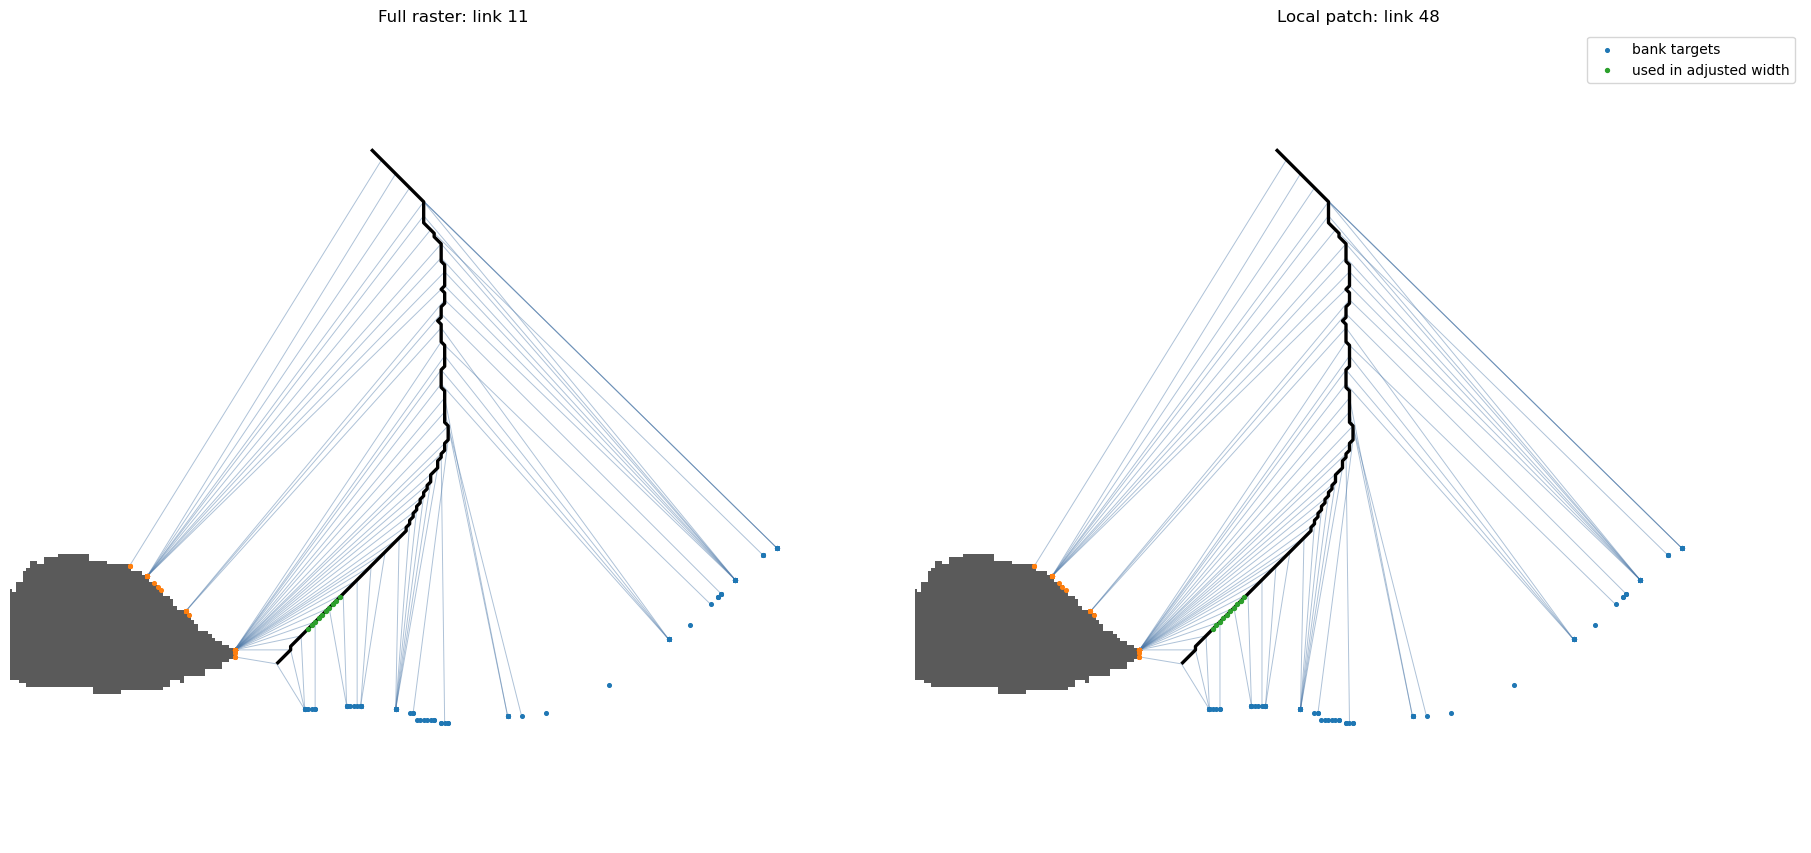

In [6]:
import matplotlib.pyplot as plt
from rasterio.windows import from_bounds, bounds as window_bounds

FULL_REVIEW_LINK_ID = 11
LOCAL_REVIEW_LINK_ID = 48
PLOT_EVERY_NTH_SAMPLE = 4
WIDTH_DIAGNOSTIC_PAD_M = 250

def final_bank_labels_path(paths, backend):
    if backend == 'full':
        return paths['routing_width_links'].parent / 'bank_labels.tif'
    candidates = sorted(path for path in paths['collapsed_mask'].parent.glob('*bank_labels.tif') if not path.name.startswith('._'))
    if len(candidates) != 1:
        raise FileNotFoundError(f'Expected one final local bank-label raster, found {candidates}')
    return candidates[0]

def width_samples(paths, link_id):
    samples_path = paths['routing_width_links'].parent / 'link_width_samples.csv'
    frame = pd.read_csv(samples_path)
    frame = frame.loc[frame['id_link'].eq(link_id)].sort_values('sample_index').reset_index(drop=True)
    if frame.empty:
        raise ValueError(f'No saved width samples for link {link_id}: {samples_path}')
    return frame

def draw_width_transects(ax, *, paths, links, link_id, samples, title, aoi, representative_link_id=None):
    bank_path = final_bank_labels_path(paths, 'full' if paths is full_paths else 'local')
    with rasterio.open(bank_path) as dataset:
        window = from_bounds(*aoi, transform=dataset.transform).round_offsets().round_lengths()
        labels = dataset.read(1, window=window, boundless=True, fill_value=0)
        left, bottom, right, top = window_bounds(window, dataset.transform)
    ax.imshow(np.where(labels > 1, labels, np.nan), extent=(left, right, bottom, top), origin='upper', cmap='Greys', alpha=0.65, interpolation='nearest', zorder=0)

    link = links.loc[links['id_link'].eq(link_id)]
    link.plot(ax=ax, color='black', linewidth=2.4, zorder=3)
    if representative_link_id is not None:
        representative = links.loc[links['id_link'].eq(representative_link_id)]
        if not representative.empty:
            representative.plot(ax=ax, color='#d627a8', linewidth=2.0, linestyle='--', label=f'width representative {representative_link_id}', zorder=3)
    valid = samples.loc[~samples['width_invalid'].fillna(False)].copy()
    plotted = valid.iloc[::PLOT_EVERY_NTH_SAMPLE]
    for row in plotted.itertuples():
        ax.plot([row.left_bank_x, row.x, row.right_bank_x], [row.left_bank_y, row.y, row.right_bank_y], color='#4C78A8', alpha=0.45, linewidth=0.7, zorder=2)
    ax.scatter(valid['left_bank_x'], valid['left_bank_y'], s=7, color='#1f77b4', label='bank targets', zorder=4)
    ax.scatter(valid['right_bank_x'], valid['right_bank_y'], s=7, color='#ff7f0e', zorder=4)
    retained = valid.loc[valid['used_in_selected_width'].fillna(False)]
    ax.scatter(retained['x'], retained['y'], s=8, color='#2ca02c', label='used in adjusted width', zorder=5)
    ax.set_title(title)
    ax.set_xlim(aoi[0], aoi[2]); ax.set_ylim(aoi[1], aoi[3]); ax.set_aspect('equal'); ax.set_axis_off()

full_review_samples = width_samples(full_paths, FULL_REVIEW_LINK_ID)
local_review_samples = width_samples(local_paths, LOCAL_REVIEW_LINK_ID)
all_x = np.r_[full_review_samples[['x', 'left_bank_x', 'right_bank_x']].to_numpy().ravel(), local_review_samples[['x', 'left_bank_x', 'right_bank_x']].to_numpy().ravel()]
all_y = np.r_[full_review_samples[['y', 'left_bank_y', 'right_bank_y']].to_numpy().ravel(), local_review_samples[['y', 'left_bank_y', 'right_bank_y']].to_numpy().ravel()]
aoi = (all_x.min() - WIDTH_DIAGNOSTIC_PAD_M, all_y.min() - WIDTH_DIAGNOSTIC_PAD_M, all_x.max() + WIDTH_DIAGNOSTIC_PAD_M, all_y.max() + WIDTH_DIAGNOSTIC_PAD_M)

full_final_link = full_links.loc[full_links['id_link'].eq(FULL_REVIEW_LINK_ID)].iloc[0]
local_final_link = local_links.loc[local_links['id_link'].eq(LOCAL_REVIEW_LINK_ID)].iloc[0]
local_representative = pd.to_numeric(pd.Series([local_final_link.get('family_width_inherited_from_link')]), errors='coerce').iloc[0]
local_representative = int(local_representative) if pd.notna(local_representative) else None
summary = pd.DataFrame([
    {'backend': 'full raster', 'link_id': FULL_REVIEW_LINK_ID, 'n_samples': len(full_review_samples), 'samples_used': int(full_review_samples['used_in_selected_width'].sum()), 'median_total_m': full_review_samples['width_total'].median(), 'median_wet_m': full_review_samples['width_wet'].median(), 'median_dry_m': full_review_samples['width_dry'].median(), 'final_wid_adj_total_m': full_final_link['wid_adj_total'], 'final_wid_adj_wet_m': full_final_link['wid_adj_wet'], 'final_wid_adj_dry_m': full_final_link['wid_adj_dry'], 'final_wid_adj_routing_m': full_final_link['wid_adj_routing'], 'segmented_stub_inheritance': full_final_link.get('family_width_inheritance_applied', False), 'representative_link_id': full_final_link.get('family_width_inherited_from_link', pd.NA)},
    {'backend': 'local patch', 'link_id': LOCAL_REVIEW_LINK_ID, 'n_samples': len(local_review_samples), 'samples_used': int(local_review_samples['used_in_selected_width'].sum()), 'median_total_m': local_review_samples['width_total'].median(), 'median_wet_m': local_review_samples['width_wet'].median(), 'median_dry_m': local_review_samples['width_dry'].median(), 'final_wid_adj_total_m': local_final_link['wid_adj_total'], 'final_wid_adj_wet_m': local_final_link['wid_adj_wet'], 'final_wid_adj_dry_m': local_final_link['wid_adj_dry'], 'final_wid_adj_routing_m': local_final_link['wid_adj_routing'], 'segmented_stub_inheritance': local_final_link.get('family_width_inheritance_applied', False), 'representative_link_id': local_final_link.get('family_width_inherited_from_link', pd.NA)},
])
display(summary)

figure, axes = plt.subplots(1, 2, figsize=(18, 9), constrained_layout=True)
draw_width_transects(axes[0], paths=full_paths, links=full_links, link_id=FULL_REVIEW_LINK_ID, samples=full_review_samples, title=f'Full raster: link {FULL_REVIEW_LINK_ID}', aoi=aoi)
draw_width_transects(axes[1], paths=local_paths, links=local_links, link_id=LOCAL_REVIEW_LINK_ID, samples=local_review_samples, title=f'Local patch: link {LOCAL_REVIEW_LINK_ID}', aoi=aoi, representative_link_id=local_representative)
axes[1].legend(loc='upper right')
plt.show()


## Review checklist

After inspecting the five sections, record decisions separately for:

- whether the full-raster fallback should accept or explicitly implement the two-link routing-width exclusion argument;
- how panelized fallback lineage should provide forced parent hydraulic-anchor matches;
- what residual/success threshold makes example 37 equivalent-resistance values acceptable;
- whether unit 126's matched domain and widths physically justify the extreme Lambda_K;
- which local fallback reasons should remain conservative fallbacks versus receive a general geometric fix.
